In [ ]:
print("Bank Customer Churn Prediction Project")
print("Project setup successful!")

Bank Customer Churn Prediction Project
Project setup successful!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving European_Bank - European_Bank.pdf to European_Bank - European_Bank.pdf


In [ ]:
!pip install pdfplumber


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 105.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 121.2 MB/s eta 0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0


In [ ]:
import pdfplumber

pdf_path = "European_Bank - European_Bank.pdf"

with pdfplumber.open(pdf_path) as pdf:
    print("Number of pages:", len(pdf.pages))


Number of pages: 205


In [ ]:
import pdfplumber

pdf_path = "European_Bank - European_Bank.pdf"

all_text = ""

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        text = page.extract_text()
        if text:
            all_text += text + "\n"

print(all_text[:5000])


Year CustomerId Surname CreditScore Geography Gender Age Tenure Balance NumOfProducts HasCrCard IsActiveMember EstimatedSalary Exited
2025 15634602 Hargrave 619 France Female 42 2 0 1 1 1 101348.88 1
2025 15647311Hill 608 Spain Female 41 1 83807.86 1 0 1 112542.58 0
2025 15619304 Onio 502 France Female 42 8 159660.8 3 1 0 113931.57 1
2025 15701354 Boni 699 France Female 39 1 0 2 0 0 93826.63 0
2025 15737888 Mitchell 850 Spain Female 43 2 125510.82 1 1 1 79084.1 0
2025 15574012 Chu 645 Spain Male 44 8 113755.78 2 1 0 149756.71 1
2025 15592531 Bartlett 822 France Male 50 7 0 2 1 1 10062.8 0
2025 15656148 Obinna 376 Germany Female 29 4 115046.74 4 1 0 119346.88 1
2025 15792365 He 501 France Male 44 4 142051.07 2 0 1 74940.5 0
2025 15592389 H? 684 France Male 27 2 134603.88 1 1 1 71725.73 0
2025 15767821 Bearce 528 France Male 31 6 102016.72 2 0 0 80181.12 0
2025 15737173 Andrews 497 Spain Male 24 3 0 2 1 0 76390.01 0
2025 15632264 Kay 476 France Female 34 10 0 2 1 0 26260.98 0
2025 156914

In [ ]:
import pdfplumber
import pandas as pd

pdf_path = "European_Bank - European_Bank.pdf"

all_tables = []

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        tables = page.extract_tables()
        for table in tables:
            if table:
                all_tables.extend(table)

print("Total rows extracted:", len(all_tables))


Total rows extracted: 10001


In [ ]:
for row in all_tables[:5]:
    print(row)

['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
['2025', '15634602', 'Hargrave', '619', 'France', 'Female', '42', '2', '0', '1', '1', '1', '101348.88', '1']
['2025', '15647311', 'Hill', '608', 'Spain', 'Female', '41', '1', '83807.86', '1', '0', '1', '112542.58', '0']
['2025', '15619304', 'Onio', '502', 'France', 'Female', '42', '8', '159660.8', '3', '1', '0', '113931.57', '1']
['2025', '15701354', 'Boni', '699', 'France', 'Female', '39', '1', '0', '2', '0', '0', '93826.63', '0']


In [ ]:
columns = [
    "Year",
    "CustomerId",
    "Surname",
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

df = pd.DataFrame(all_tables[1:], columns=columns)

print(df.shape)
df.head()

(10000, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.8,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.1,0


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Exited"].value_counts())

Dataset Shape: (10000, 14)

Column Names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Missing Values:
Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate Rows:
0

Churn Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [ ]:
df.describe()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000
unique,1,10000,2932,511,3,2,70,11,6382,4,2,2,9999,2
top,2025,15656710,Smith,850,France,Male,37,2,0,1,1,1,24924.92,0
freq,10000,1,32,231,5014,5457,478,1048,3617,5084,7055,5151,2,7963


In [ ]:
# Step 11: Data Cleaning

# Remove completely empty rows
df = df.dropna(how="all")

# Remove duplicate customers based on CustomerId
df = df.drop_duplicates(subset="CustomerId")

# Convert numerical columns to numeric format
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:")
print(df.shape)

Missing values after cleaning:
Year                0
CustomerId          0
Surname             0
CreditScore        51
Geography           0
Gender              0
Age                 0
Tenure              0
Balance             0
NumOfProducts       0
HasCrCard           0
IsActiveMember      0
EstimatedSalary     0
Exited              0
dtype: int64

Dataset shape after cleaning:
(10000, 14)


In [ ]:
print(df["Exited"].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


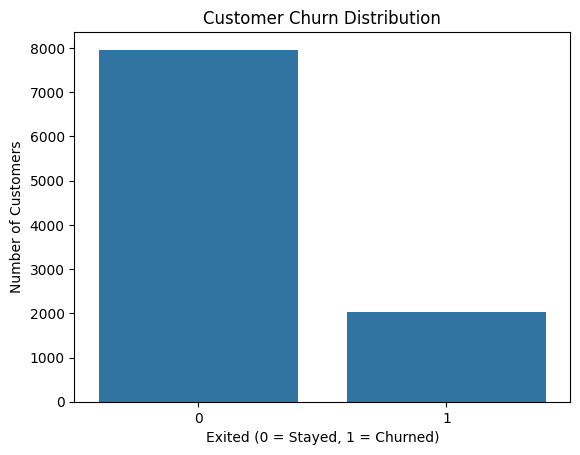

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Exited")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
churn_percentage = df["Exited"].value_counts(normalize=True) * 100

print(f"Customers Stayed: {churn_percentage.get(0, 0):.2f}%")
print(f"Customers Churned: {churn_percentage.get(1, 0):.2f}%")

Customers Stayed: 79.63%
Customers Churned: 20.37%


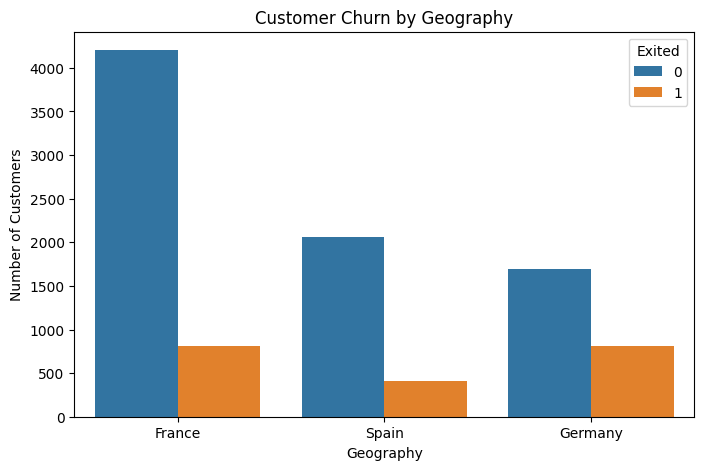

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Geography", hue="Exited")

plt.title("Customer Churn by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")
plt.show()

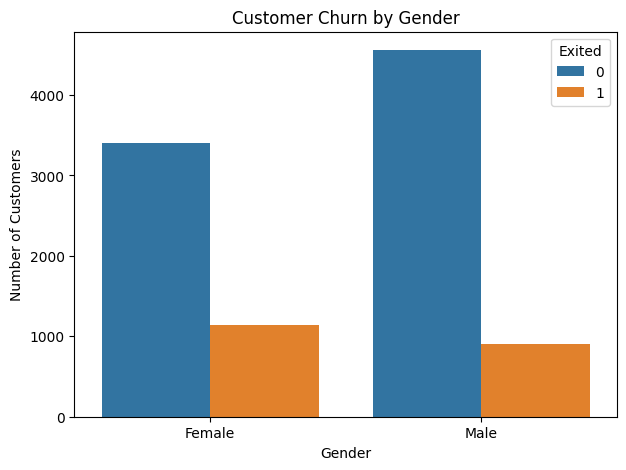

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Gender", hue="Exited")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

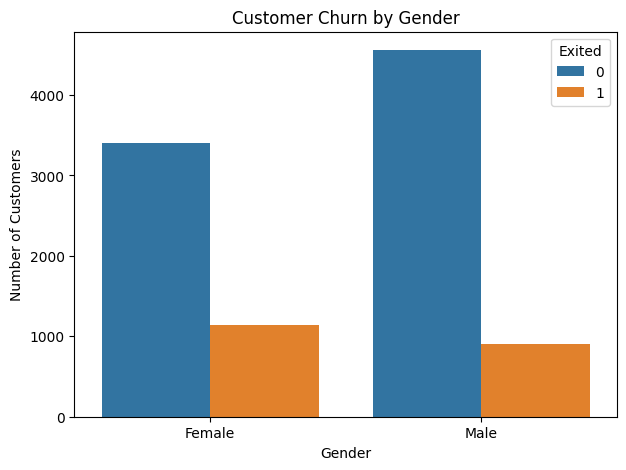

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Gender", hue="Exited")

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

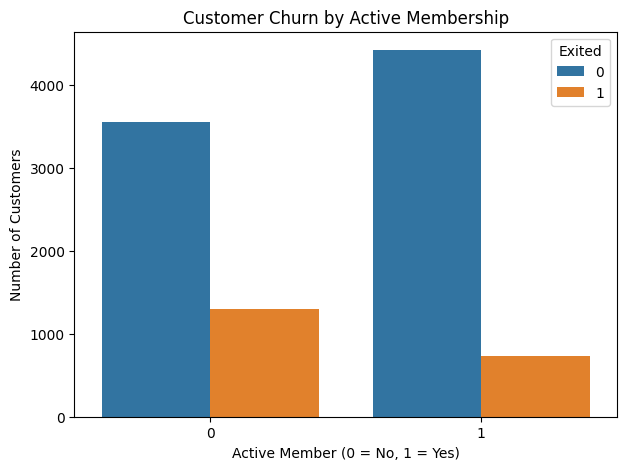

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="IsActiveMember", hue="Exited")

plt.title("Customer Churn by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

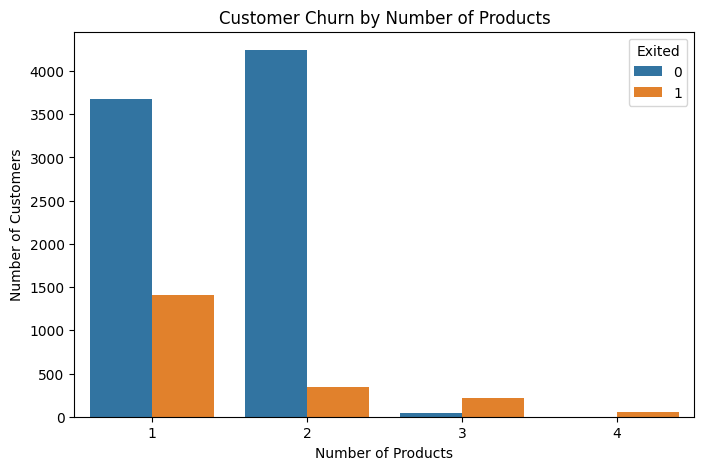

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="NumOfProducts", hue="Exited")

plt.title("Customer Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")
plt.show()

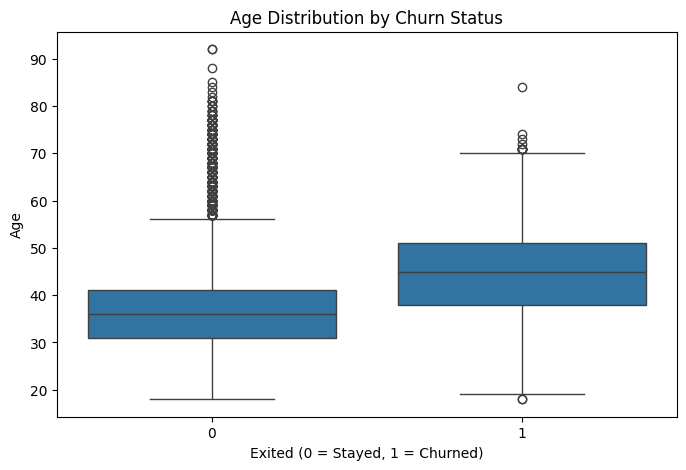

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Exited", y="Age")

plt.title("Age Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Age")
plt.show()

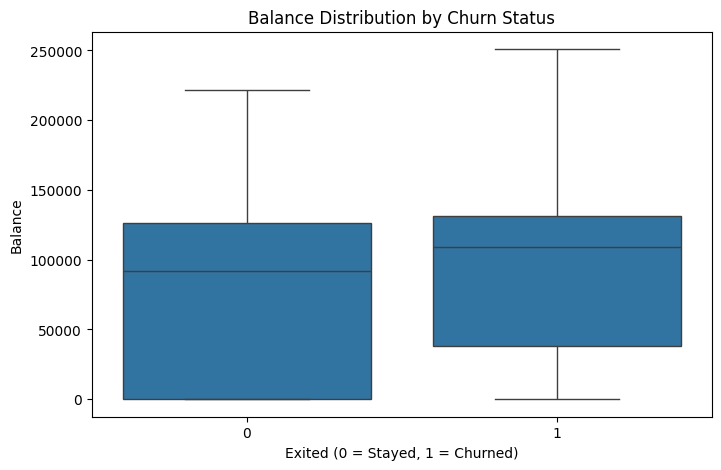

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Exited", y="Balance")

plt.title("Balance Distribution by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Balance")
plt.show()

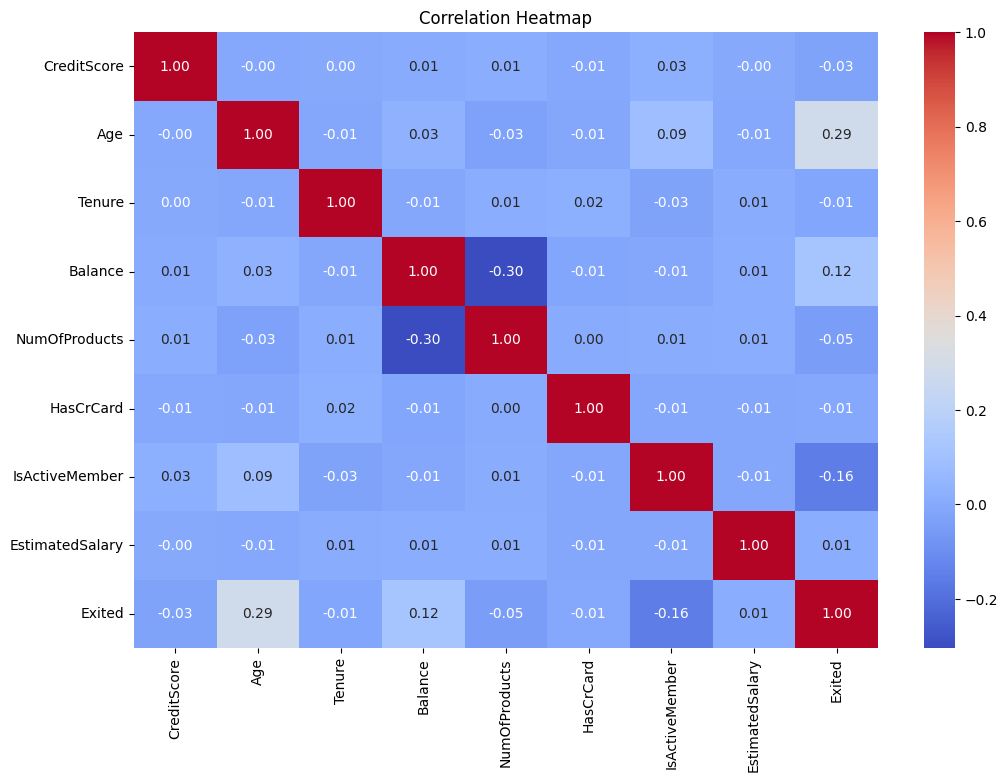

In [ ]:
correlation = df[numeric_columns].corr()

plt.figure(figsize=(12,8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
print("Total Customers:", len(df))
print("Customers Churned:", (df["Exited"] == 1).sum())
print("Customers Stayed:", (df["Exited"] == 0).sum())

print("\nChurn Rate:")
print(f"{df['Exited'].mean() * 100:.2f}%")

Total Customers: 10000
Customers Churned: 2037
Customers Stayed: 7963

Churn Rate:
20.37%


In [ ]:
# Create a copy for machine learning
ml_df = df.copy()

# Remove columns that are not useful for prediction
ml_df = ml_df.drop(columns=["CustomerId", "Surname"])

print("Remaining columns:")
print(ml_df.columns.tolist())

Remaining columns:
['Year', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [ ]:
# Convert categorical variables into numerical variables

ml_df = pd.get_dummies(
    ml_df,
    columns=["Geography", "Gender"],
    drop_first=True
)

print(ml_df.head())
print("\nNew columns:")
print(ml_df.columns.tolist())

   Year  CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0  2025        619.0   42       2       0.00              1          1   
1  2025        608.0   41       1   83807.86              1          0   
2  2025        502.0   42       8  159660.80              3          1   
3  2025        699.0   39       1       0.00              2          0   
4  2025        850.0   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1              False   
1               1        112542.58       0              False   
2               0        113931.57       1              False   
3               0         93826.63       0              False   
4               1         79084.10       0              False   

   Geography_Spain  Gender_Male  
0            False        False  
1             True        False  
2            False        False  
3            False        Fa

In [ ]:
X = ml_df.drop(columns=["Exited"])
y = ml_df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 12)
y shape: (10000,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 12)
Testing data: (2000, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [ ]:
# Fill missing CreditScore values with the median
X["CreditScore"] = X["CreditScore"].fillna(X["CreditScore"].median())

print("Missing CreditScore values:", X["CreditScore"].isnull().sum())

Missing CreditScore values: 0


In [ ]:
!pip install pdfplumber

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 90.0 MB/s eta 0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0


In [ ]:
import pandas as pd
import numpy as np
import pdfplumber

In [ ]:
!pip install pdfplumber

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving European_Bank - European_Bank.pdf to European_Bank - European_Bank.pdf


In [ ]:
import os

print(os.listdir())

['.config', 'European_Bank - European_Bank.pdf', 'sample_data']


In [ ]:
pdf_path = "/content/European_Bank - European_Bank.pdf"

print("File found:", os.path.exists(pdf_path))

File found: True


In [ ]:
for row in all_tables[:5]:
    print(row)

['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
['2025', '15634602', 'Hargrave', '619', 'France', 'Female', '42', '2', '0', '1', '1', '1', '101348.88', '1']
['2025', '15647311', 'Hill', '608', 'Spain', 'Female', '41', '1', '83807.86', '1', '0', '1', '112542.58', '0']
['2025', '15619304', 'Onio', '502', 'France', 'Female', '42', '8', '159660.8', '3', '1', '0', '113931.57', '1']
['2025', '15701354', 'Boni', '699', 'France', 'Female', '39', '1', '0', '2', '0', '0', '93826.63', '0']


In [ ]:
import pandas as pd

columns = [
    "Year",
    "CustomerId",
    "Surname",
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

# Keep only rows having 14 columns
valid_rows = [row for row in all_tables if len(row) == 14]

df = pd.DataFrame(valid_rows, columns=columns)

# Remove repeated header rows
df = df[df["CustomerId"].astype(str) != "CustomerId"].copy()

# Convert numeric columns
numeric_columns = [
    "Year",
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows where target is missing
df = df.dropna(subset=["Exited"])

# Fill missing Credit Score
df["CreditScore"] = df["CreditScore"].fillna(df["CreditScore"].median())

# Remove duplicate customers
df = df.drop_duplicates(subset="CustomerId")

print("Dataset created successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset created successfully!
Shape: (1665, 14)


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
1,2025,15634602,Hargrave,619.0,France,Female,42,2,0.00,1,1,1,101348.88,1
2,2025,15647311,Hill,608.0,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,2025,15619304,Onio,502.0,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,2025,15701354,Boni,699.0,France,Female,39,1,0.00,2,0,0,93826.63,0
5,2025,15737888,Mitchell,850.0,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
print(df.isnull().sum())

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [ ]:
# Make a copy for Machine Learning
ml_df = df.copy()

# Remove columns that are not useful for prediction
ml_df = ml_df.drop(columns=["CustomerId", "Surname"], errors="ignore")

# Convert categorical columns into numbers
ml_df = pd.get_dummies(
    ml_df,
    columns=["Geography", "Gender"],
    drop_first=True
)

# Convert True/False into 1/0
ml_df = ml_df.astype(float)

# Separate features and target
X = ml_df.drop(columns=["Exited"])
y = ml_df["Exited"].astype(int)

# Fill any remaining missing values
X = X.fillna(X.median())

print("ML preparation completed!")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nRemaining missing values:")
print(X.isnull().sum().sum())

ML preparation completed!
X shape: (1665, 12)
y shape: (1665,)

Target distribution:
Exited
0    1314
1     351
Name: count, dtype: int64

Remaining missing values:
0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train-Test Split Completed!")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Train-Test Split Completed!
Training data: (1332, 12)
Testing data: (333, 12)
Training target: (1332,)
Testing target: (333,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Feature scaling completed!
Training data shape: (1332, 12)
Testing data shape: (333, 12)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
model_lr = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred_lr[:10])

Predictions completed!
First 10 predictions:
[0 0 0 0 0 1 0 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, zero_division=0)
recall = recall_score(y_test, y_pred_lr, zero_division=0)
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

MODEL PERFORMANCE
-------------------------
Accuracy : 81.68 %
Precision: 62.86 %
Recall   : 31.43 %
F1 Score : 41.9 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89       263
           1       0.63      0.31      0.42        70

    accuracy                           0.82       333
   macro avg       0.73      0.63      0.66       333
weighted avg       0.79      0.82      0.79       333


Confusion Matrix:
[[250  13]
 [ 48  22]]


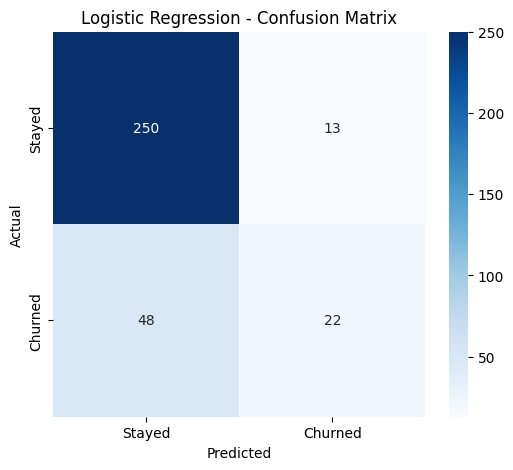

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred_rf = model_rf.predict(X_test)

print("Random Forest predictions completed!")
print("First 10 predictions:")
print(y_pred_rf[:10])

Random Forest predictions completed!
First 10 predictions:
[1 0 0 0 0 1 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

print("RANDOM FOREST PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy_rf * 100, 2), "%")
print("Precision:", round(precision_rf * 100, 2), "%")
print("Recall   :", round(recall_rf * 100, 2), "%")
print("F1 Score :", round(f1_rf * 100, 2), "%")

RANDOM FOREST PERFORMANCE
-------------------------
Accuracy : 84.98 %
Precision: 75.0 %
Recall   : 42.86 %
F1 Score : 54.55 %


In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1
    ],
    "Random Forest": [
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf
    ]
})

comparison["Logistic Regression"] = (
    comparison["Logistic Regression"] * 100
).round(2)

comparison["Random Forest"] = (
    comparison["Random Forest"] * 100
).round(2)

display(comparison)

,Metric,Logistic Regression,Random Forest
0,Accuracy,81.68,84.98
1,Precision,62.86,75.00
2,Recall,31.43,42.86
3,F1 Score,41.90,54.55


In [ ]:
if f1_rf > f1:
    best_model = model_rf
    best_model_name = "Random Forest"
    best_predictions = y_pred_rf
else:
    best_model = model_lr
    best_model_name = "Logistic Regression"
    best_predictions = y_pred_lr

print("BEST MODEL:", best_model_name)
print("F1 Score:", round(max(f1_rf, f1) * 100, 2), "%")

BEST MODEL: Random Forest
F1 Score: 54.55 %


In [ ]:
# Get churn probability from the best model
churn_probability = best_model.predict_proba(X)[:, 1]

# Add probability to the original dataset
risk_df = df.copy()

risk_df["Churn_Probability"] = churn_probability

# Convert probability into percentage
risk_df["Churn_Probability_%"] = (
    risk_df["Churn_Probability"] * 100
).round(2)

display(
    risk_df[
        ["CustomerId", "Surname", "Age", "Balance",
         "IsActiveMember", "Churn_Probability_%"]
    ].head(10)
)

,CustomerId,Surname,Age,Balance,IsActiveMember,Churn_Probability_%
1,15634602,Hargrave,42,0.00,1,69.0
2,15647311,Hill,41,83807.86,1,10.0
3,15619304,Onio,42,159660.80,0,91.0
4,15701354,Boni,39,0.00,0,33.0
5,15737888,Mitchell,43,125510.82,1,6.0
6,15574012,Chu,44,113755.78,0,71.0
7,15592531,Bartlett,50,0.00,1,2.0
8,15656148,Obinna,29,115046.74,0,58.0
9,15792365,He,44,142051.07,1,3.0
10,15592389,H?,27,134603.88,1,0.0


In [ ]:
def assign_risk(probability):
    if probability < 0.30:
        return "Low Risk"
    elif probability < 0.60:
        return "Medium Risk"
    else:
        return "High Risk"

risk_df["Risk_Category"] = risk_df["Churn_Probability"].apply(assign_risk)

print("Risk categories created successfully!")

print("\nRisk Distribution:")
print(risk_df["Risk_Category"].value_counts())

display(
    risk_df[
        ["CustomerId", "Surname", "Churn_Probability_%",
         "Risk_Category"]
    ].head(10)
)

Risk categories created successfully!

Risk Distribution:
Risk_Category
Low Risk       1304
High Risk       309
Medium Risk      52
Name: count, dtype: int64


,CustomerId,Surname,Churn_Probability_%,Risk_Category
1,15634602,Hargrave,69.0,High Risk
2,15647311,Hill,10.0,Low Risk
3,15619304,Onio,91.0,High Risk
4,15701354,Boni,33.0,Medium Risk
5,15737888,Mitchell,6.0,Low Risk
6,15574012,Chu,71.0,High Risk
7,15592531,Bartlett,2.0,Low Risk
8,15656148,Obinna,58.0,Medium Risk
9,15792365,He,3.0,Low Risk
10,15592389,H?,0.0,Low Risk


In [ ]:
high_risk_customers = risk_df[
    risk_df["Risk_Category"] == "High Risk"
].copy()

# Sort from highest to lowest churn probability
high_risk_customers = high_risk_customers.sort_values(
    by="Churn_Probability",
    ascending=False
)

print("Number of High-Risk Customers:", len(high_risk_customers))

display(
    high_risk_customers[
        [
            "CustomerId",
            "Surname",
            "Geography",
            "Gender",
            "Age",
            "Balance",
            "NumOfProducts",
            "IsActiveMember",
            "Churn_Probability_%",
            "Risk_Category"
        ]
    ].head(20)
)

Number of High-Risk Customers: 309


,CustomerId,Surname,Geography,Gender,Age,Balance,NumOfProducts,IsActiveMember,Churn_Probability_%,Risk_Category
545,15802593,Little,France,Female,49,0.00,3,1,100.0,High Risk
1319,15665077,Vogel,France,Female,43,0.00,3,1,99.0,High Risk
89,15622897,Sharpe,France,Female,46,0.00,3,0,99.0,High Risk
744,15641675,Kirillova,France,Female,49,88915.37,3,0,98.0,High Risk
1006,15701602,Ayers,Germany,Male,52,116497.31,3,0,97.0,High Risk
556,15775318,Lu,Spain,Female,51,154962.99,3,1,97.0,High Risk
239,15794056,Johnston,France,Female,46,0.00,3,0,97.0,High Risk
91,15757535,Heap,Spain,Female,44,0.00,3,1,96.0,High Risk
872,15692750,McGregor,Germany,Female,45,129818.39,3,0,96.0,High Risk
1613,15649121,Pinto,France,Male,52,0.00,1,0,96.0,High Risk


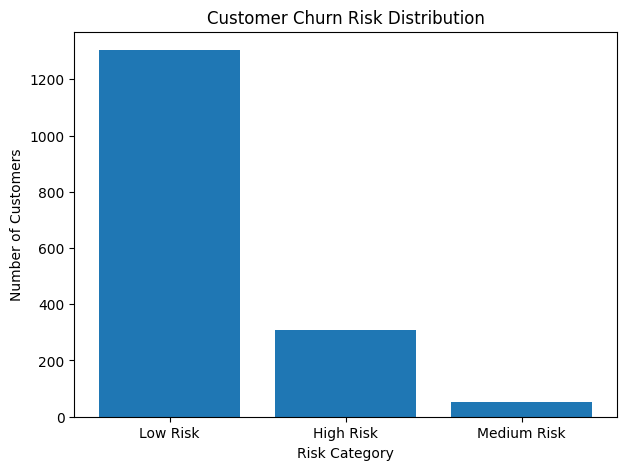

In [ ]:
import matplotlib.pyplot as plt

risk_counts = risk_df["Risk_Category"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(risk_counts.index, risk_counts.values)

plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Risk Distribution")

plt.show()

In [ ]:
# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP CHURN PREDICTION FACTORS")

display(feature_importance.head(10))

TOP CHURN PREDICTION FACTORS


,Feature,Importance
2,Age,0.237699
8,EstimatedSalary,0.141585
1,CreditScore,0.136172
5,NumOfProducts,0.130754
4,Balance,0.123470
3,Tenure,0.085829
7,IsActiveMember,0.057651
11,Gender_Male,0.024769
9,Geography_Germany,0.024593
6,HasCrCard,0.020413


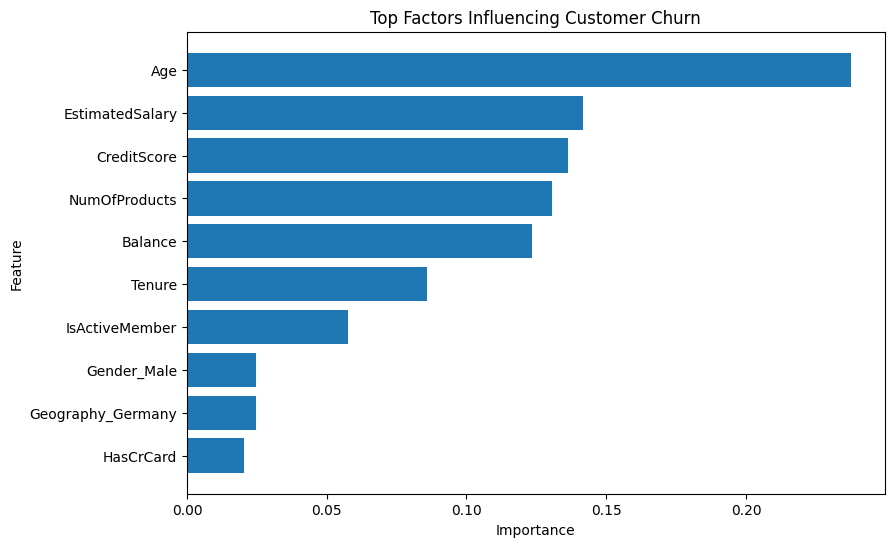

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Factors Influencing Customer Churn")
plt.show()

In [ ]:
final_risk_table = risk_df[
    [
        "CustomerId",
        "Surname",
        "Geography",
        "Gender",
        "Age",
        "Tenure",
        "Balance",
        "NumOfProducts",
        "HasCrCard",
        "IsActiveMember",
        "EstimatedSalary",
        "Churn_Probability_%",
        "Risk_Category"
    ]
].copy()

# Show highest-risk customers first
final_risk_table = final_risk_table.sort_values(
    by="Churn_Probability_%",
    ascending=False
)

display(final_risk_table.head(20))

,CustomerId,Surname,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Churn_Probability_%,Risk_Category
545,15802593,Little,France,Female,49,7,0.00,3,0,1,87822.14,100.0,High Risk
89,15622897,Sharpe,France,Female,46,4,0.00,3,1,0,93251.42,99.0,High Risk
1319,15665077,Vogel,France,Female,43,5,0.00,3,1,1,100722.72,99.0,High Risk
744,15641675,Kirillova,France,Female,49,2,88915.37,3,0,0,161435.02,98.0,High Risk
239,15794056,Johnston,France,Female,46,2,0.00,3,1,0,89048.46,97.0,High Risk
556,15775318,Lu,Spain,Female,51,3,154962.99,3,0,1,191932.27,97.0,High Risk
1006,15701602,Ayers,Germany,Male,52,5,116497.31,3,0,0,53793.10,97.0,High Risk
872,15692750,McGregor,Germany,Female,45,7,129818.39,3,1,0,9217.55,96.0,High Risk
91,15757535,Heap,Spain,Female,44,5,0.00,3,1,1,174205.22,96.0,High Risk
1613,15649121,Pinto,France,Male,52,3,0.00,1,1,0,116137.01,96.0,High Risk


In [ ]:
# Save complete risk table
output_file = "Bank_Customer_Churn_Risk_Scoring.xlsx"

final_risk_table.to_excel(output_file, index=False)

print("File saved successfully!")
print(output_file)

File saved successfully!
Bank_Customer_Churn_Risk_Scoring.xlsx


In [ ]:
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
total_customers = len(risk_df)
high_risk = (risk_df["Risk_Category"] == "High Risk").sum()
medium_risk = (risk_df["Risk_Category"] == "Medium Risk").sum()
low_risk = (risk_df["Risk_Category"] == "Low Risk").sum()

actual_churn = risk_df["Exited"].sum()
churn_rate = (actual_churn / total_customers) * 100

print("======================================")
print(" BANK CUSTOMER CHURN PROJECT SUMMARY")
print("======================================")

print("Total Customers       :", total_customers)
print("Customers Churned     :", actual_churn)
print("Overall Churn Rate    :", round(churn_rate, 2), "%")

print("\nRISK DISTRIBUTION")
print("-------------------------")
print("High Risk Customers   :", high_risk)
print("Medium Risk Customers :", medium_risk)
print("Low Risk Customers    :", low_risk)

print("\nBEST MODEL")
print("-------------------------")
print("Model                  :", best_model_name)

if best_model_name == "Random Forest":
    print("Accuracy               :", round(accuracy_rf * 100, 2), "%")
    print("Precision              :", round(precision_rf * 100, 2), "%")
    print("Recall                 :", round(recall_rf * 100, 2), "%")
    print("F1 Score               :", round(f1_rf * 100, 2), "%")
else:
    print("Accuracy               :", round(accuracy * 100, 2), "%")
    print("Precision              :", round(precision * 100, 2), "%")
    print("Recall                 :", round(recall * 100, 2), "%")
    print("F1 Score               :", round(f1 * 100, 2), "%")

 BANK CUSTOMER CHURN PROJECT SUMMARY
Total Customers       : 1665
Customers Churned     : 351
Overall Churn Rate    : 21.08 %

RISK DISTRIBUTION
-------------------------
High Risk Customers   : 309
Medium Risk Customers : 52
Low Risk Customers    : 1304

BEST MODEL
-------------------------
Model                  : Random Forest
Accuracy               : 84.98 %
Precision              : 75.0 %
Recall                 : 42.86 %
F1 Score               : 54.55 %


In [ ]:
print("""
========================================
      CUSTOMER CHURN RECOMMENDATIONS
========================================

1. HIGH-RISK CUSTOMERS
   - Contact high-risk customers proactively.
   - Provide personalized offers and retention benefits.
   - Assign priority to customers with very high churn probability.

2. CUSTOMER ENGAGEMENT
   - Encourage inactive customers to use banking services.
   - Send personalized messages, offers and service updates.

3. PRODUCT STRATEGY
   - Review customers having very few or too many products.
   - Recommend suitable banking products based on customer needs.

4. CUSTOMER RETENTION
   - Provide loyalty rewards to valuable customers.
   - Improve customer support and service experience.

5. DATA-DRIVEN MONITORING
   - Continuously update the churn prediction model.
   - Monitor customer risk scores regularly.

6. BUSINESS BENEFIT
   - Early identification of customers likely to leave
     can help the bank take preventive retention actions.
   - This can help reduce customer churn and improve
     customer lifetime value.
""")


      CUSTOMER CHURN RECOMMENDATIONS

1. HIGH-RISK CUSTOMERS
   - Contact high-risk customers proactively.
   - Provide personalized offers and retention benefits.
   - Assign priority to customers with very high churn probability.

2. CUSTOMER ENGAGEMENT
   - Encourage inactive customers to use banking services.
   - Send personalized messages, offers and service updates.

3. PRODUCT STRATEGY
   - Review customers having very few or too many products.
   - Recommend suitable banking products based on customer needs.

4. CUSTOMER RETENTION
   - Provide loyalty rewards to valuable customers.
   - Improve customer support and service experience.

5. DATA-DRIVEN MONITORING
   - Continuously update the churn prediction model.
   - Monitor customer risk scores regularly.

6. BUSINESS BENEFIT
   - Early identification of customers likely to leave
     can help the bank take preventive retention actions.
   - This can help reduce customer churn and improve
     customer lifetime value.



In [ ]:
# Dashboard summary data

dashboard_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Churned Customers",
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ],
    "Value": [
        total_customers,
        actual_churn,
        low_risk,
        medium_risk,
        high_risk
    ]
})

display(dashboard_summary)

,Metric,Value
0,Total Customers,1665
1,Churned Customers,351
2,Low Risk,1304
3,Medium Risk,52
4,High Risk,309


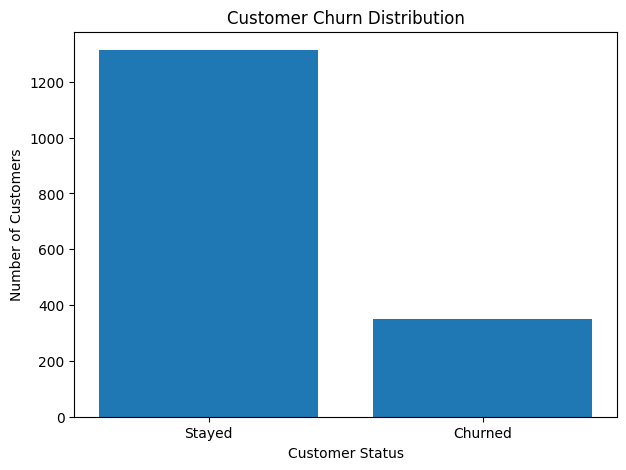

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Stayed", "Churned"],
    [
        total_customers - actual_churn,
        actual_churn
    ]
)

plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")

plt.show()

In [ ]:
import plotly.express as px

# Risk category chart
risk_chart = px.pie(
    risk_df,
    names="Risk_Category",
    title="Customer Churn Risk Distribution"
)

risk_chart.show()

In [ ]:
geo_data = (
    risk_df.groupby("Geography")["Exited"]
    .mean()
    .reset_index()
)

geo_data["Churn_Rate_%"] = (geo_data["Exited"] * 100).round(2)

geo_chart = px.bar(
    geo_data,
    x="Geography",
    y="Churn_Rate_%",
    title="Churn Rate by Geography",
    text="Churn_Rate_%"
)

geo_chart.show()

In [ ]:
age_chart = px.histogram(
    risk_df,
    x="Age",
    color="Exited",
    nbins=20,
    title="Customer Age and Churn"
)

age_chart.show()

In [ ]:
# Top 20 high-risk customers

top_20_risk = risk_df.sort_values(
    by="Churn_Probability_%",
    ascending=False
).head(20)

dashboard_table = top_20_risk[
    [
        "CustomerId",
        "Surname",
        "Geography",
        "Age",
        "Balance",
        "NumOfProducts",
        "IsActiveMember",
        "Churn_Probability_%",
        "Risk_Category"
    ]
]

display(dashboard_table)

,CustomerId,Surname,Geography,Age,Balance,NumOfProducts,IsActiveMember,Churn_Probability_%,Risk_Category
545,15802593,Little,France,49,0.00,3,1,100.0,High Risk
89,15622897,Sharpe,France,46,0.00,3,0,99.0,High Risk
1319,15665077,Vogel,France,43,0.00,3,1,99.0,High Risk
744,15641675,Kirillova,France,49,88915.37,3,0,98.0,High Risk
239,15794056,Johnston,France,46,0.00,3,0,97.0,High Risk
556,15775318,Lu,Spain,51,154962.99,3,1,97.0,High Risk
1006,15701602,Ayers,Germany,52,116497.31,3,0,97.0,High Risk
872,15692750,McGregor,Germany,45,129818.39,3,0,96.0,High Risk
91,15757535,Heap,Spain,44,0.00,3,1,96.0,High Risk
1613,15649121,Pinto,France,52,0.00,1,0,96.0,High Risk


In [ ]:
print("========== PROJECT RESULTS ==========")

print("Total Customers:", total_customers)
print("Churned Customers:", actual_churn)
print("Churn Rate:", round(churn_rate, 2), "%")

print("\nRisk Categories:")
print("High Risk:", high_risk)
print("Medium Risk:", medium_risk)
print("Low Risk:", low_risk)

print("\nBest Model:", best_model_name)

print("\nModel Performance:")
if best_model_name == "Random Forest":
    print("Accuracy:", round(accuracy_rf * 100, 2), "%")
    print("Precision:", round(precision_rf * 100, 2), "%")
    print("Recall:", round(recall_rf * 100, 2), "%")
    print("F1 Score:", round(f1_rf * 100, 2), "%")
else:
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall:", round(recall * 100, 2), "%")
    print("F1 Score:", round(f1 * 100, 2), "%")

========== PROJECT RESULTS ==========
Total Customers: 1665
Churned Customers: 351
Churn Rate: 21.08 %

Risk Categories:
High Risk: 309
Medium Risk: 52
Low Risk: 1304

Best Model: Random Forest

Model Performance:
Accuracy: 84.98 %
Precision: 75.0 %
Recall: 42.86 %
F1 Score: 54.55 %
